<a href="https://colab.research.google.com/github/StivenR1128/cifar10_web_demo/blob/Stiven_Rodas/CIFAR10_Red_Densa_Entrenamiento_Incompleto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10 con una red neuronal densa
## Entrenamiento, evolución de la pérdida y evaluación

**Objetivo:** entrenar una red densa para clasificar imágenes de CIFAR-10 en 10 categorías, observar la evolución de la función de pérdida y el accuracy, y registrar cuántas épocas se utilizaron.

> CIFAR-10 contiene imágenes RGB de 32 × 32 píxeles. Para usar una red densa, cada imagen se aplana a un vector de 3.072 valores. En este experimento la pérdida principal será *categorical cross-entropy*, apropiada para clasificación multiclase. También registraremos MSE como métrica complementaria, no como función de pérdida principal.

**Requisitos:** TensorFlow 2.x, NumPy y Matplotlib. Puede ejecutarse en Google Colab o en un entorno local con TensorFlow instalado.

In [4]:
# Si lo necesitas en un entorno local, descomenta:
# %pip install tensorflow matplotlib numpy

import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Dispositivos:", tf.config.list_physical_devices())

TensorFlow: 2.21.0
Dispositivos: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU'), PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Cargar y preparar los datos

Usaremos el conjunto oficial de entrenamiento para crear dos particiones: entrenamiento y validación. El conjunto de prueba se reserva para la evaluación final, después del entrenamiento.

In [5]:
import hashlib
import os
import pickle
import tarfile
import urllib.request

class_names = [
    "Avión", "Automóvil", "Ave", "Gato", "Ciervo",
    "Perro", "Rana", "Caballo", "Barco", "Camión"
]

# Espejo del archivo oficial de CIFAR-10 en Hugging Face.
# El MD5 se comprueba para asegurar que el archivo sea íntegro.
archive_url = "https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/c6e562aecc3a2dd5ee13f9d91630d81219c6a126/cifar-10-python.tar.gz"
archive_path = "/content/cifar-10-python.tar.gz"
expected_md5 = "c58f30108f718f92721af3b95e74349a"

def file_md5(path):
    digest = hashlib.md5()
    with open(path, "rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

if not os.path.exists(archive_path) or file_md5(archive_path) != expected_md5:
    print("Descargando CIFAR-10 desde un espejo del archivo oficial...")
    urllib.request.urlretrieve(archive_url, archive_path)

if file_md5(archive_path) != expected_md5:
    raise ValueError("El archivo descargado de CIFAR-10 no pasó la verificación MD5.")

extract_dir = "/content"
with tarfile.open(archive_path, "r:gz") as archive:
    archive.extractall(path=extract_dir)

data_dir = os.path.join(extract_dir, "cifar-10-batches-py")

def load_cifar_batch(filename):
    with open(os.path.join(data_dir, filename), "rb") as file:
        batch = pickle.load(file, encoding="bytes")
    images = batch[b"data"].reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1)
    labels = np.asarray(batch[b"labels"], dtype=np.int64).reshape(-1, 1)
    return images, labels

train_batches = [load_cifar_batch(f"data_batch_{i}") for i in range(1, 6)]
x_train_full = np.concatenate([batch[0] for batch in train_batches], axis=0)
y_train_full = np.concatenate([batch[1] for batch in train_batches], axis=0)
x_test, y_test = load_cifar_batch("test_batch")

# Convertir píxeles de [0, 255] a [0, 1]
x_train_full = x_train_full.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Convertir las etiquetas a vectores one-hot para categorical cross-entropy.
y_train_full_onehot = tf.keras.utils.to_categorical(y_train_full.squeeze(), 10)
y_test_onehot = tf.keras.utils.to_categorical(y_test.squeeze(), 10)

# Mezclar de forma reproducible y separar 5.000 imágenes para validación.
rng = np.random.default_rng(42)
indices = rng.permutation(len(x_train_full))
val_idx = indices[:5000]
train_idx = indices[5000:]

x_val, y_val = x_train_full[val_idx], y_train_full_onehot[val_idx]
x_train, y_train = x_train_full[train_idx], y_train_full_onehot[train_idx]

print(f"Entrenamiento: {x_train.shape[0]} imágenes")
print(f"Validación:     {x_val.shape[0]} imágenes")
print(f"Prueba:         {x_test.shape[0]} imágenes")
print("Forma de cada imagen:", x_train.shape[1:])

/tmp/ipykernel_3392/1765232298.py:34: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  archive.extractall(path=extract_dir)


Entrenamiento: 45000 imágenes
Validación:     5000 imágenes
Prueba:         10000 imágenes
Forma de cada imagen: (32, 32, 3)


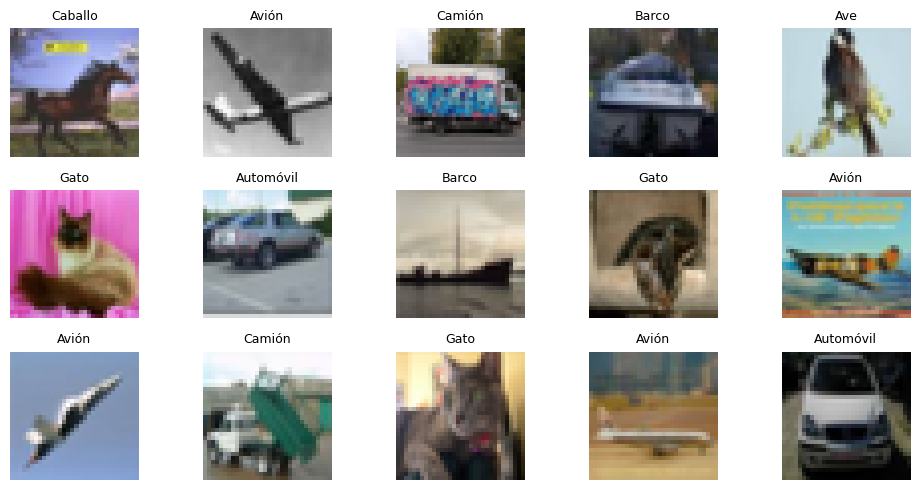

In [6]:
# Visualizar algunas imágenes y sus etiquetas
plt.figure(figsize=(10, 5))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[np.argmax(y_train[i])], fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Construir una red neuronal densa

La capa `Flatten` transforma cada imagen de 32 × 32 × 3 en un vector de 3.072 características. Después, las capas `Dense` aprenden combinaciones de esas características. Esta arquitectura sirve como línea base; no aprovecha explícitamente la estructura espacial de la imagen como lo haría una CNN.

Fijate bien en los comentarios para terminar el código faltante.

In [7]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(512, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy", tf.keras.metrics.MeanSquaredError(name="mse")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,707,274 (6.51 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Entrenar y registrar las épocas

El entrenamiento permite hasta 40 épocas con un batch size de 128, pero `EarlyStopping` puede detenerlo antes si la pérdida de validación deja de mejorar. Por eso, el número real de épocas se obtiene de `len(history.history["loss"])`, no se supone de antemano.

In [8]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True, verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6, verbose=1)
]

max_epochs = 40
batch_size = 128
start_time = time.time()

history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=max_epochs,
    batch_size=batch_size,
    callbacks=callbacks,
    verbose=1
)

elapsed_seconds = time.time() - start_time
epochs_used = len(history.history["loss"])
best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

print(f"\nÉpocas ejecutadas: {epochs_used} de {max_epochs} máximas")
print(f"Época con menor val_loss: {best_epoch}")
print(f"Tiempo de entrenamiento: {elapsed_seconds / 60:.2f} minutos")
print(f"Menor pérdida de validación registrada: {min(history.history['val_loss']):.4f}")

Epoch 1/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.2598 - loss: 2.0205 - mse: 0.0835 - val_accuracy: 0.3356 - val_loss: 1.8550 - val_mse: 0.0792 - learning_rate: 0.0010
Epoch 2/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3104 - loss: 1.8798 - mse: 0.0799 - val_accuracy: 0.3494 - val_loss: 1.7918 - val_mse: 0.0776 - learning_rate: 0.0010
Epoch 3/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3340 - loss: 1.8271 - mse: 0.0783 - val_accuracy: 0.3768 - val_loss: 1.7466 - val_mse: 0.0759 - learning_rate: 0.0010
Epoch 4/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3497 - loss: 1.7874 - mse: 0.0770 - val_accuracy: 0.3858 - val_loss: 1.7063 - val_mse: 0.0747 - learning_rate: 0.0010
Epoch 5/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.3585 - loss: 1.7672 - mse: 0.0764 - val_accuracy: 0.4014 - val_loss: 1.7035 - val_mse: 0.0744 - learning_rate: 0.0010
Epoch 6/40
352/352 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3627 - loss: 

## 4. Graficar la evolución del entrenamiento

- **Loss:** entropía cruzada; es la función que el optimizador intenta minimizar.
- **MSE:** error cuadrático medio entre las probabilidades predichas y las etiquetas one-hot; se registra como métrica complementaria.
- **Accuracy:** proporción de imágenes clasificadas correctamente.

Compara las curvas de entrenamiento y validación. Si la pérdida de entrenamiento sigue bajando mientras la de validación deja de mejorar o sube, puede haber sobreajuste.

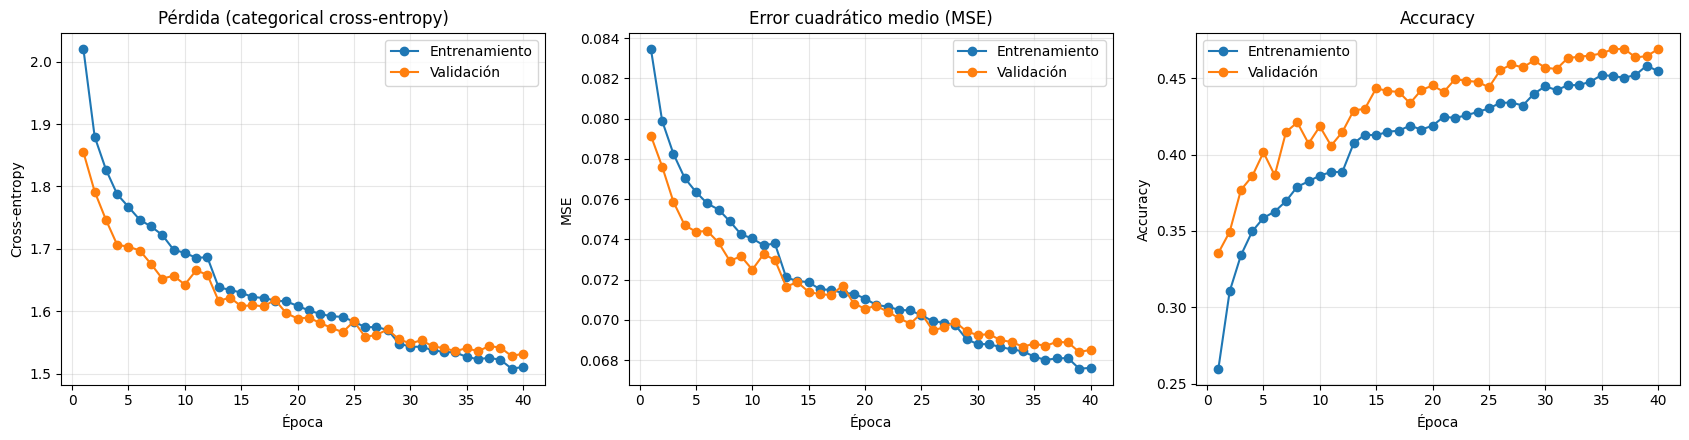

In [9]:
epochs_range = range(1, epochs_used + 1)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# Pérdida principal: categorical cross-entropy
axes[0].plot(epochs_range, history.history["loss"], marker="o", label="Entrenamiento")
axes[0].plot(epochs_range, history.history["val_loss"], marker="o", label="Validación")
axes[0].set_title("Pérdida (categorical cross-entropy)")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Cross-entropy")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# MSE complementario
axes[1].plot(epochs_range, history.history["mse"], marker="o", label="Entrenamiento")
axes[1].plot(epochs_range, history.history["val_mse"], marker="o", label="Validación")
axes[1].set_title("Error cuadrático medio (MSE)")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("MSE")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Accuracy
axes[2].plot(epochs_range, history.history["accuracy"], marker="o", label="Entrenamiento")
axes[2].plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validación")
axes[2].set_title("Accuracy")
axes[2].set_xlabel("Época")
axes[2].set_ylabel("Accuracy")
axes[2].grid(True, alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

## 5. Evaluación final con el conjunto de prueba

El conjunto de prueba no se utilizó para ajustar los pesos ni para elegir la época. Esta evaluación ofrece una estimación final del desempeño sobre datos reservados.

In [10]:
test_results = model.evaluate(x_test, y_test_onehot, verbose=0)
test_loss, test_accuracy, test_mse = test_results

print(f"Test loss (cross-entropy): {test_loss:.4f}")
print(f"Test accuracy:             {test_accuracy:.2%}")
print(f"Test MSE:                  {test_mse:.4f}")

Test loss (cross-entropy): 1.5149
Test accuracy:             47.46%
Test MSE:                  0.0678


# Realizar completamente la parte de verificación de entrenamiento

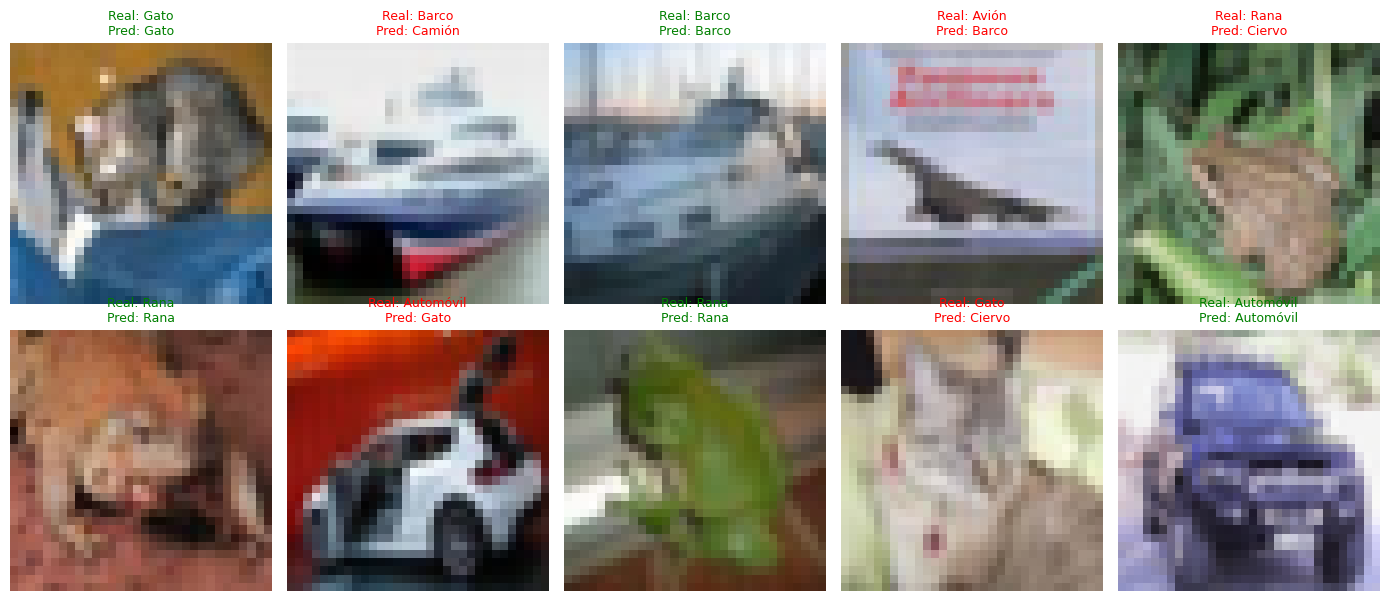

Aciertos en las 10 imágenes mostradas: 5/10
Verificación completada: se compararon las predicciones con sus etiquetas reales.


In [11]:
# Predicciones para 10 imágenes reservadas para prueba
probabilidades = model.predict(x_test[:10], verbose=0)
predicciones = np.argmax(probabilidades, axis=1)
etiquetas_reales = y_test[:10].squeeze()

fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i])
    real = class_names[int(etiquetas_reales[i])]
    predicha = class_names[int(predicciones[i])]
    color = "green" if etiquetas_reales[i] == predicciones[i] else "red"
    ax.set_title(f"Real: {real}\nPred: {predicha}", color=color, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

aciertos = int(np.sum(predicciones == etiquetas_reales))
print(f"Aciertos en las 10 imágenes mostradas: {aciertos}/10")
print("Verificación completada: se compararon las predicciones con sus etiquetas reales.")

## 6. Guardar el modelo

El archivo `.keras` conserva la arquitectura y los pesos para volver a cargar el modelo en Python. Para ejecutarlo directamente en un navegador, posteriormente se puede convertir a TensorFlow.js; esa conversión requiere preparar el entorno correspondiente.

In [12]:
import os

# Guardar el modelo entrenado en el almacenamiento temporal de Colab
model_path = "/content/cifar10_dense_model.keras"
model.save(model_path)
print("Modelo guardado en:", model_path)
print("Tamaño:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")

Modelo guardado en: /content/cifar10_dense_model.keras
Tamaño: 19.57 MB


In [13]:
from google.colab import files

files.download("/content/cifar10_dense_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>